## **Bitcoin 2019 Historical Closing Price**

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import matplotlib.ticker as mticker
from matplotlib.dates import DateFormatter
import datetime as dt

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("jkraak/bitcoin-price-dataset")

print("Path to dataset files:", path)

100%|██████████| 127M/127M [00:00<00:00, 175MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/jkraak/bitcoin-price-dataset/versions/1


In [5]:
df = pd.read_csv(path+"/bitcoin_2017_to_2023.csv")

print(df.count())
print(df.columns)
print(df.index)

timestamp                       3126000
open                            3126000
high                            3126000
low                             3126000
close                           3126000
volume                          3126000
quote_asset_volume              3126000
number_of_trades                3126000
taker_buy_base_asset_volume     3126000
taker_buy_quote_asset_volume    3126000
dtype: int64
Index(['timestamp', 'open', 'high', 'low', 'close', 'volume',
       'quote_asset_volume', 'number_of_trades', 'taker_buy_base_asset_volume',
       'taker_buy_quote_asset_volume'],
      dtype='object')
RangeIndex(start=0, stop=3126000, step=1)


In [6]:
print(df.head())

             timestamp      open      high       low     close    volume  \
0  2023-08-01 13:19:00  28902.48  28902.49  28902.48  28902.49   4.68658   
1  2023-08-01 13:18:00  28902.48  28902.49  28902.48  28902.49   4.77589   
2  2023-08-01 13:17:00  28908.52  28908.53  28902.48  28902.49  11.52263   
3  2023-08-01 13:16:00  28907.41  28912.74  28907.41  28908.53  15.89610   
4  2023-08-01 13:15:00  28896.00  28907.42  28893.03  28907.41  37.74657   

   quote_asset_volume  number_of_trades  taker_buy_base_asset_volume  \
0        1.354538e+05               258                      0.89391   
1        1.380351e+05               317                      2.24546   
2        3.330532e+05               451                      2.70873   
3        4.595556e+05               483                     10.22981   
4        1.090761e+06               686                     16.50452   

   taker_buy_quote_asset_volume  
0                  25836.224836  
1                  64899.385195  
2       

In [10]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df[df['timestamp'].dt.year == 2019]
print(df)

                  timestamp     open     high      low    close     volume  \
1883164 2019-12-31 23:59:00  7195.20  7196.42  7193.46  7195.23   4.486104   
1883165 2019-12-31 23:58:00  7190.79  7196.07  7190.79  7195.87   4.488904   
1883166 2019-12-31 23:57:00  7193.80  7196.04  7190.17  7190.17  11.425707   
1883167 2019-12-31 23:56:00  7205.88  7205.90  7192.06  7194.08  50.279127   
1883168 2019-12-31 23:55:00  7204.25  7206.29  7203.28  7205.90   5.358492   
...                     ...      ...      ...      ...      ...        ...   
2407432 2019-01-01 00:02:00  3699.42  3702.04  3696.08  3698.14  14.488615   
2407433 2019-01-01 00:01:00  3702.44  3702.63  3695.66  3697.04  23.700604   
2407434 2019-01-01 00:01:00  3702.44  3702.63  3695.66  3697.04  23.700604   
2407435 2019-01-01 00:00:00  3701.23  3703.72  3701.09  3702.46  17.100110   
2407436 2019-01-01 00:00:00  3701.23  3703.72  3701.09  3702.46  17.100110   

         quote_asset_volume  number_of_trades  taker_buy_base_a

In [24]:
df_indexed = df.set_index('timestamp')
# Calculate the daily average
daily_avg_resample = df_indexed.resample('D').mean()
print(daily_avg_resample)
max_price = daily_avg_resample['close'].max()
max_date = daily_avg_resample['close'].idxmax()

                   open         high          low        close     volume  \
timestamp                                                                   
2019-01-01  3701.894513  3703.710900  3700.070432  3701.969030  15.713316   
2019-01-02  3800.654549  3802.876375  3798.594167  3800.687347  24.414211   
2019-01-03  3802.009326  3803.647243  3800.260833  3801.935771  20.421492   
2019-01-04  3761.847160  3763.629569  3760.059771  3761.866521  20.499691   
2019-01-05  3800.629764  3802.329097  3798.956194  3800.604167  21.174075   
...                 ...          ...          ...          ...        ...   
2019-12-27  7209.985681  7212.617896  7207.348771  7210.011972  23.362987   
2019-12-28  7311.693931  7314.124153  7309.254181  7311.746674  18.645127   
2019-12-29  7356.650069  7359.078062  7354.281194  7356.708729  21.796601   
2019-12-30  7317.053271  7319.264667  7314.658604  7316.944868  20.559661   
2019-12-31  7223.406257  7225.604097  7221.037965  7223.407431  18.023926   

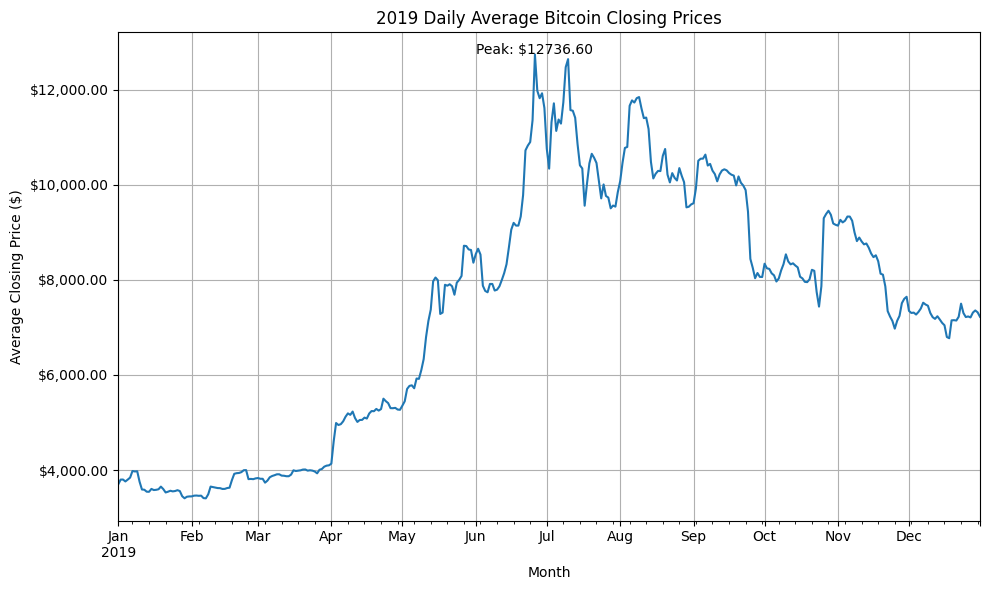

In [30]:
ax = daily_avg_resample['close'].plot(kind='line', figsize=(10, 6), title='2019 Daily Average Bitcoin Closing Prices')
formatter = mticker.StrMethodFormatter('${x:,.2f}')
ax.yaxis.set_major_formatter(formatter)
ax.annotate(f'Peak: ${max_price:.2f}',
            xy=(max_date, max_price),
            xytext=(max_date, max_price + 20),
            ha='center')
plt.xlabel("Month")
plt.ylabel("Average Closing Price ($)")
plt.tight_layout()
plt.grid(True)
plt.show()